# Exploratory Data Analysis Starter

## Import packages

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
pd.set_option('display.max_columns', 100)

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

---

## Loading data with Pandas

We need to load `client_data.csv` and `price_data.csv` into individual dataframes so that we can work with them in Python. For this notebook and all further notebooks, it will be assumed that the CSV files will the placed in the same file location as the notebook. If they are not, please adjust the directory within the `read_csv` method accordingly.

In [2]:
import os

# Define path to raw data (works whether executed from root or notebooks/)
DATA_RAW_DIR = "../data/raw" if os.path.exists("../data/raw") else "data/raw"

client_df = pd.read_csv(os.path.join(DATA_RAW_DIR, "client_data.csv"))
price_df = pd.read_csv(os.path.join(DATA_RAW_DIR, "price_data.csv"))


You can view the first 3 rows of a dataframe using the `head` method. Similarly, if you wanted to see the last 3, you can use `tail(3)`

In [3]:
client_df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0


In [4]:
price_df.head(3)

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0


---

## Descriptive statistics of data

### Data types

It is useful to first understand the data that you're dealing with along with the data types of each column. The data types may dictate how you transform and engineer features.

To get an overview of the data types within a data frame, use the `info()` method.

In [5]:
client_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent_12m         

In [6]:
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  193002 non-null  object 
 1   price_date          193002 non-null  object 
 2   price_off_peak_var  193002 non-null  float64
 3   price_peak_var      193002 non-null  float64
 4   price_mid_peak_var  193002 non-null  float64
 5   price_off_peak_fix  193002 non-null  float64
 6   price_peak_fix      193002 non-null  float64
 7   price_mid_peak_fix  193002 non-null  float64
dtypes: float64(6), object(2)
memory usage: 11.8+ MB


### Statistics

Now let's look at some statistics about the datasets. We can do this by using the `describe()` method.

In [7]:
client_df.describe()

,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,pow_max,churn
count,1.460600e+04,1.460600e+04,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000
mean,1.592203e+05,2.809238e+04,16090.269752,1868.614880,1399.762906,0.966726,63.086871,0.137283,0.050491,43.130056,152.786896,24.565121,24.562517,1.292346,189.264522,4.997809,18.135136,0.097152
std,5.734653e+05,1.629731e+05,64364.196422,2387.571531,3247.786255,5.108289,66.165783,0.024623,0.049037,4.485988,341.369366,20.231172,20.230280,0.709774,311.798130,1.611749,13.534743,0.296175
min,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,3.300000,0.000000
25%,5.674750e+03,0.000000e+00,0.000000,494.995000,0.000000,0.000000,16.180000,0.116340,0.000000,40.606701,0.000000,14.280000,14.280000,1.000000,50.712500,4.000000,12.500000,0.000000
50%,1.411550e+04,0.000000e+00,792.500000,1112.875000,314.000000,0.000000,18.795000,0.143166,0.084138,44.311378,37.395000,21.640000,21.640000,1.000000,112.530000,5.000000,13.856000,0.000000
75%,4.076375e+04,0.000000e+00,3383.000000,2401.790000,1745.750000,0.000000,131.030000,0.146348,0.098837,44.311378,193.980000,29.880000,29.880000,1.000000,243.097500,6.000000,19.172500,0.000000
max,6.207104e+06,4.154590e+06,771203.000000,82902.830000,175375.000000,30.000000,599.310000,0.273963,0.195975,59.266378,15042.790000,374.640000,374.640000,32.000000,24570.650000,13.000000,320.000000,1.000000


In [8]:
price_df.describe()

,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
count,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000
mean,0.141027,0.054630,0.030496,43.334477,10.622875,6.409984
std,0.025032,0.049924,0.036298,5.410297,12.841895,7.773592
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.125976,0.000000,0.000000,40.728885,0.000000,0.000000
50%,0.146033,0.085483,0.000000,44.266930,0.000000,0.000000
75%,0.151635,0.101673,0.072558,44.444710,24.339581,16.226389
max,0.280700,0.229788,0.114102,59.444710,36.490692,17.458221


---
## Data Understanding

In [9]:
client_df.isnull().sum(), price_df.isnull().sum()

(id                                0
 channel_sales                     0
 cons_12m                          0
 cons_gas_12m                      0
 cons_last_month                   0
 date_activ                        0
 date_end                          0
 date_modif_prod                   0
 date_renewal                      0
 forecast_cons_12m                 0
 forecast_cons_year                0
 forecast_discount_energy          0
 forecast_meter_rent_12m           0
 forecast_price_energy_off_peak    0
 forecast_price_energy_peak        0
 forecast_price_pow_off_peak       0
 has_gas                           0
 imp_cons                          0
 margin_gross_pow_ele              0
 margin_net_pow_ele                0
 nb_prod_act                       0
 net_margin                        0
 num_years_antig                   0
 origin_up                         0
 pow_max                           0
 churn                             0
 dtype: int64,
 id                    

In [10]:
client_df.shape, price_df.shape

((14606, 26), (193002, 8))

In [11]:
for col in client_df.columns:
    print(f"Unique Value for {col} : {client_df[col].nunique()}")

Unique Value for id : 14606
Unique Value for channel_sales : 8
Unique Value for cons_12m : 11065
Unique Value for cons_gas_12m : 2112
Unique Value for cons_last_month : 4751
Unique Value for date_activ : 1796
Unique Value for date_end : 368
Unique Value for date_modif_prod : 2129
Unique Value for date_renewal : 386
Unique Value for forecast_cons_12m : 13993
Unique Value for forecast_cons_year : 4218
Unique Value for forecast_discount_energy : 12
Unique Value for forecast_meter_rent_12m : 3528
Unique Value for forecast_price_energy_off_peak : 516
Unique Value for forecast_price_energy_peak : 329
Unique Value for forecast_price_pow_off_peak : 41
Unique Value for has_gas : 2
Unique Value for imp_cons : 7752
Unique Value for margin_gross_pow_ele : 2391
Unique Value for margin_net_pow_ele : 2391
Unique Value for nb_prod_act : 10
Unique Value for net_margin : 11965
Unique Value for num_years_antig : 13
Unique Value for origin_up : 6
Unique Value for pow_max : 698
Unique Value for churn : 2


In [12]:
for col in price_df.columns:
    print(f"Unique Value for {col} : {price_df[col].nunique()}")

Unique Value for id : 16096
Unique Value for price_date : 12
Unique Value for price_off_peak_var : 1853
Unique Value for price_peak_var : 1189
Unique Value for price_mid_peak_var : 711
Unique Value for price_off_peak_fix : 66
Unique Value for price_peak_fix : 31
Unique Value for price_mid_peak_fix : 28


---

## Data Cleaning

In [13]:
# Assuming client_df is your DataFrame
columns_to_convert = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']

# Convert specified columns to datetime
for column in columns_to_convert:
    client_df[column] = pd.to_datetime(client_df[column], errors='coerce')
    
    
price_df['price_date'] = pd.to_datetime(price_df['price_date'], errors='coerce')

---
## Feature Engineering

In [14]:
client_df['contract_duration'] = client_df['date_end'] - client_df['date_activ']
client_df['time_since_last_renewal'] = client_df['date_end'] - client_df['date_renewal']
client_df['consumption_trend '] = (client_df['cons_last_month'] / client_df['cons_12m'])
price_df['price_variability'] = price_df[['price_off_peak_var', 'price_peak_var', 'price_mid_peak_var']].std()
price_df['price_fixed'] = price_df[['price_off_peak_fix', 'price_peak_fix', 'price_mid_peak_fix']].std()

---

## Data visualization

If you're working in Python, two of the most popular packages for visualization are `matplotlib` and `seaborn`. We highly recommend you use these, or at least be familiar with them because they are ubiquitous!

Below are some functions that you can use to get started with visualizations. 

what we focus on? 
- Find Out Gas Consumption and Prices (Margin)
- Date activations and end of contract (X : date ativation,and date end y : churn)
- Date Renewal the contract 
- Find Out how long client use the product, and the reason stop use the product (assumption stop using product is because the power max, prices, and sustainability product)
- If there is a decrease in product usage, check the last date renewal. There might be correlation with product discontinuation.
- Investigate the crucial price for product
- Find out the pattern of product usage (Churn vs Not)
- electricity and gas consumption 

In [15]:
catColsClient = client_df.select_dtypes(include="object")
numColsClient = client_df.select_dtypes(exclude='object')

In [16]:
def plot_stacked_bars(dataframe, title_, size_=(18, 10), rot_=0, legend_="upper right"):
    """
    Plot stacked bars with annotations
    """
    ax = dataframe.plot(
        kind="bar",
        stacked=True,
        figsize=size_,
        rot=rot_,
        title=title_
    )

    # Annotate bars
    annotate_stacked_bars(ax, textsize=14)
    # Rename legend
    plt.legend(["Retention", "Churn"], loc=legend_)
    # Labels
    plt.ylabel("Company base (%)")
    plt.show()

def annotate_stacked_bars(ax, pad=0.99, colour="white", textsize=13):
    """
    Add value annotations to the bars
    """

    # Iterate over the plotted rectanges/bars
    for p in ax.patches:
        
        # Calculate annotation
        value = str(round(p.get_height(),1))
        # If value is 0 do not annotate
        if value == '0.0':
            continue
        ax.annotate(
            value,
            ((p.get_x()+ p.get_width()/2)*pad-0.05, (p.get_y()+p.get_height()/2)*pad),
            color=colour,
            size=textsize
        )

def plot_distribution(dataframe, column, ax, bins_=50):
    """
    Plot variable distirbution in a stacked histogram of churned or retained company
    """
    # Create a temporal dataframe with the data to be plot
    temp = pd.DataFrame({"Retention": dataframe[dataframe["churn"]==0][column],
    "Churn":dataframe[dataframe["churn"]==1][column]})
    # Plot the histogram
    temp[["Retention","Churn"]].plot(kind='hist', bins=bins_, ax=ax, stacked=True)
    # X-axis label
    ax.set_xlabel(column)
    # Change the x-axis to plain style
    ax.ticklabel_format(style='plain', axis='x')

Thhe first function `plot_stacked_bars` is used to plot a stacked bar chart. An example of how you could use this is shown below:

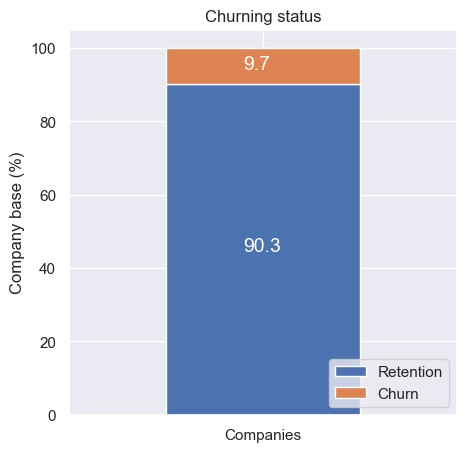

In [17]:
churn = client_df[['id', 'churn']]
churn.columns = ['Companies', 'churn']
churn_total = churn.groupby(churn['churn']).count()
churn_percentage = churn_total / churn_total.sum() * 100
plot_stacked_bars(churn_percentage.transpose(), "Churning status", (5, 5), legend_="lower right")

The second function `annotate_bars` is used by the first function, but the third function `plot_distribution` helps you to plot the distribution of a numeric column. An example of how it can be used is given below:

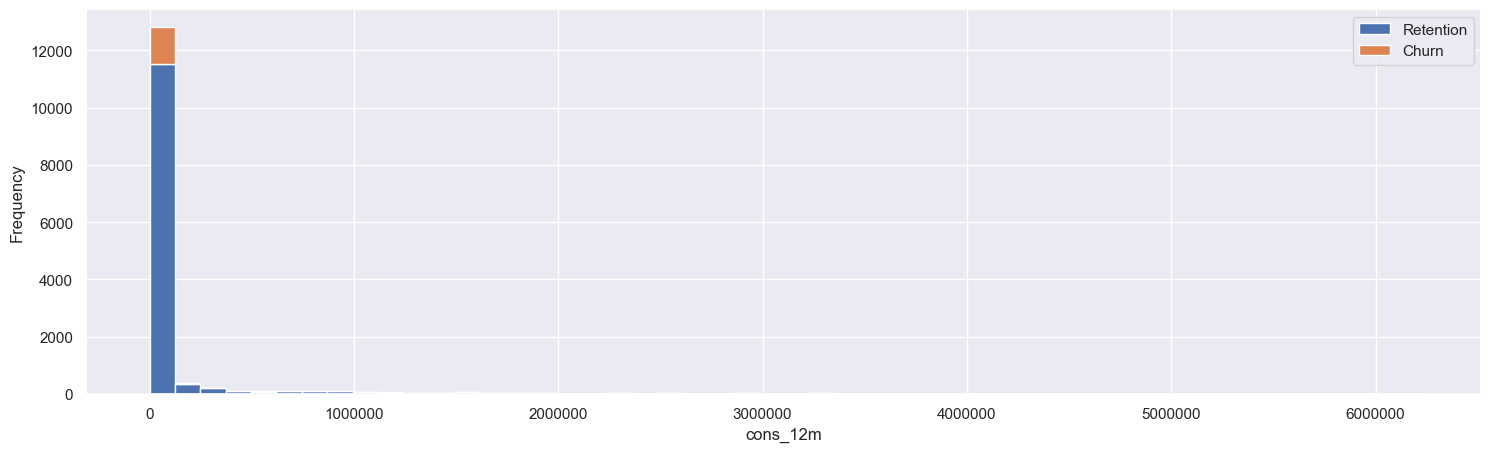

In [18]:
consumption = client_df[['id', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'imp_cons', 'has_gas', 'churn']]

fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'cons_12m', axs)

---
## EDA

In [19]:
all_ids_exist = client_df['id'].isin(price_df['id']).all()

print(f"Apakah semua ID di client_df ada di price_df? {all_ids_exist}")

price_df.drop(['price_variability','price_fixed'],axis=1,inplace=True)

client_df['consumption_trend '] = client_df['consumption_trend '].fillna(client_df['consumption_trend '].mean())

merged_df = client_df.merge(price_df, on='id', how='inner')

Apakah semua ID di client_df ada di price_df? True


C:\Users\booma\AppData\Local\Temp\ipykernel_13688\3354320933.py:21: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_churn[col], label='Churn', shade=True, color='red', common_norm=False, ax=axes[i])
C:\Users\booma\AppData\Local\Temp\ipykernel_13688\3354320933.py:22: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_no_churn[col], label='No Churn', shade=True, color='blue', common_norm=False, ax=axes[i])
C:\Users\booma\AppData\Local\Temp\ipykernel_13688\3354320933.py:21: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_churn[col], label='Churn', shade=True, color='red', common_norm=False, ax=axes[i])
C:\Users\booma\AppDat

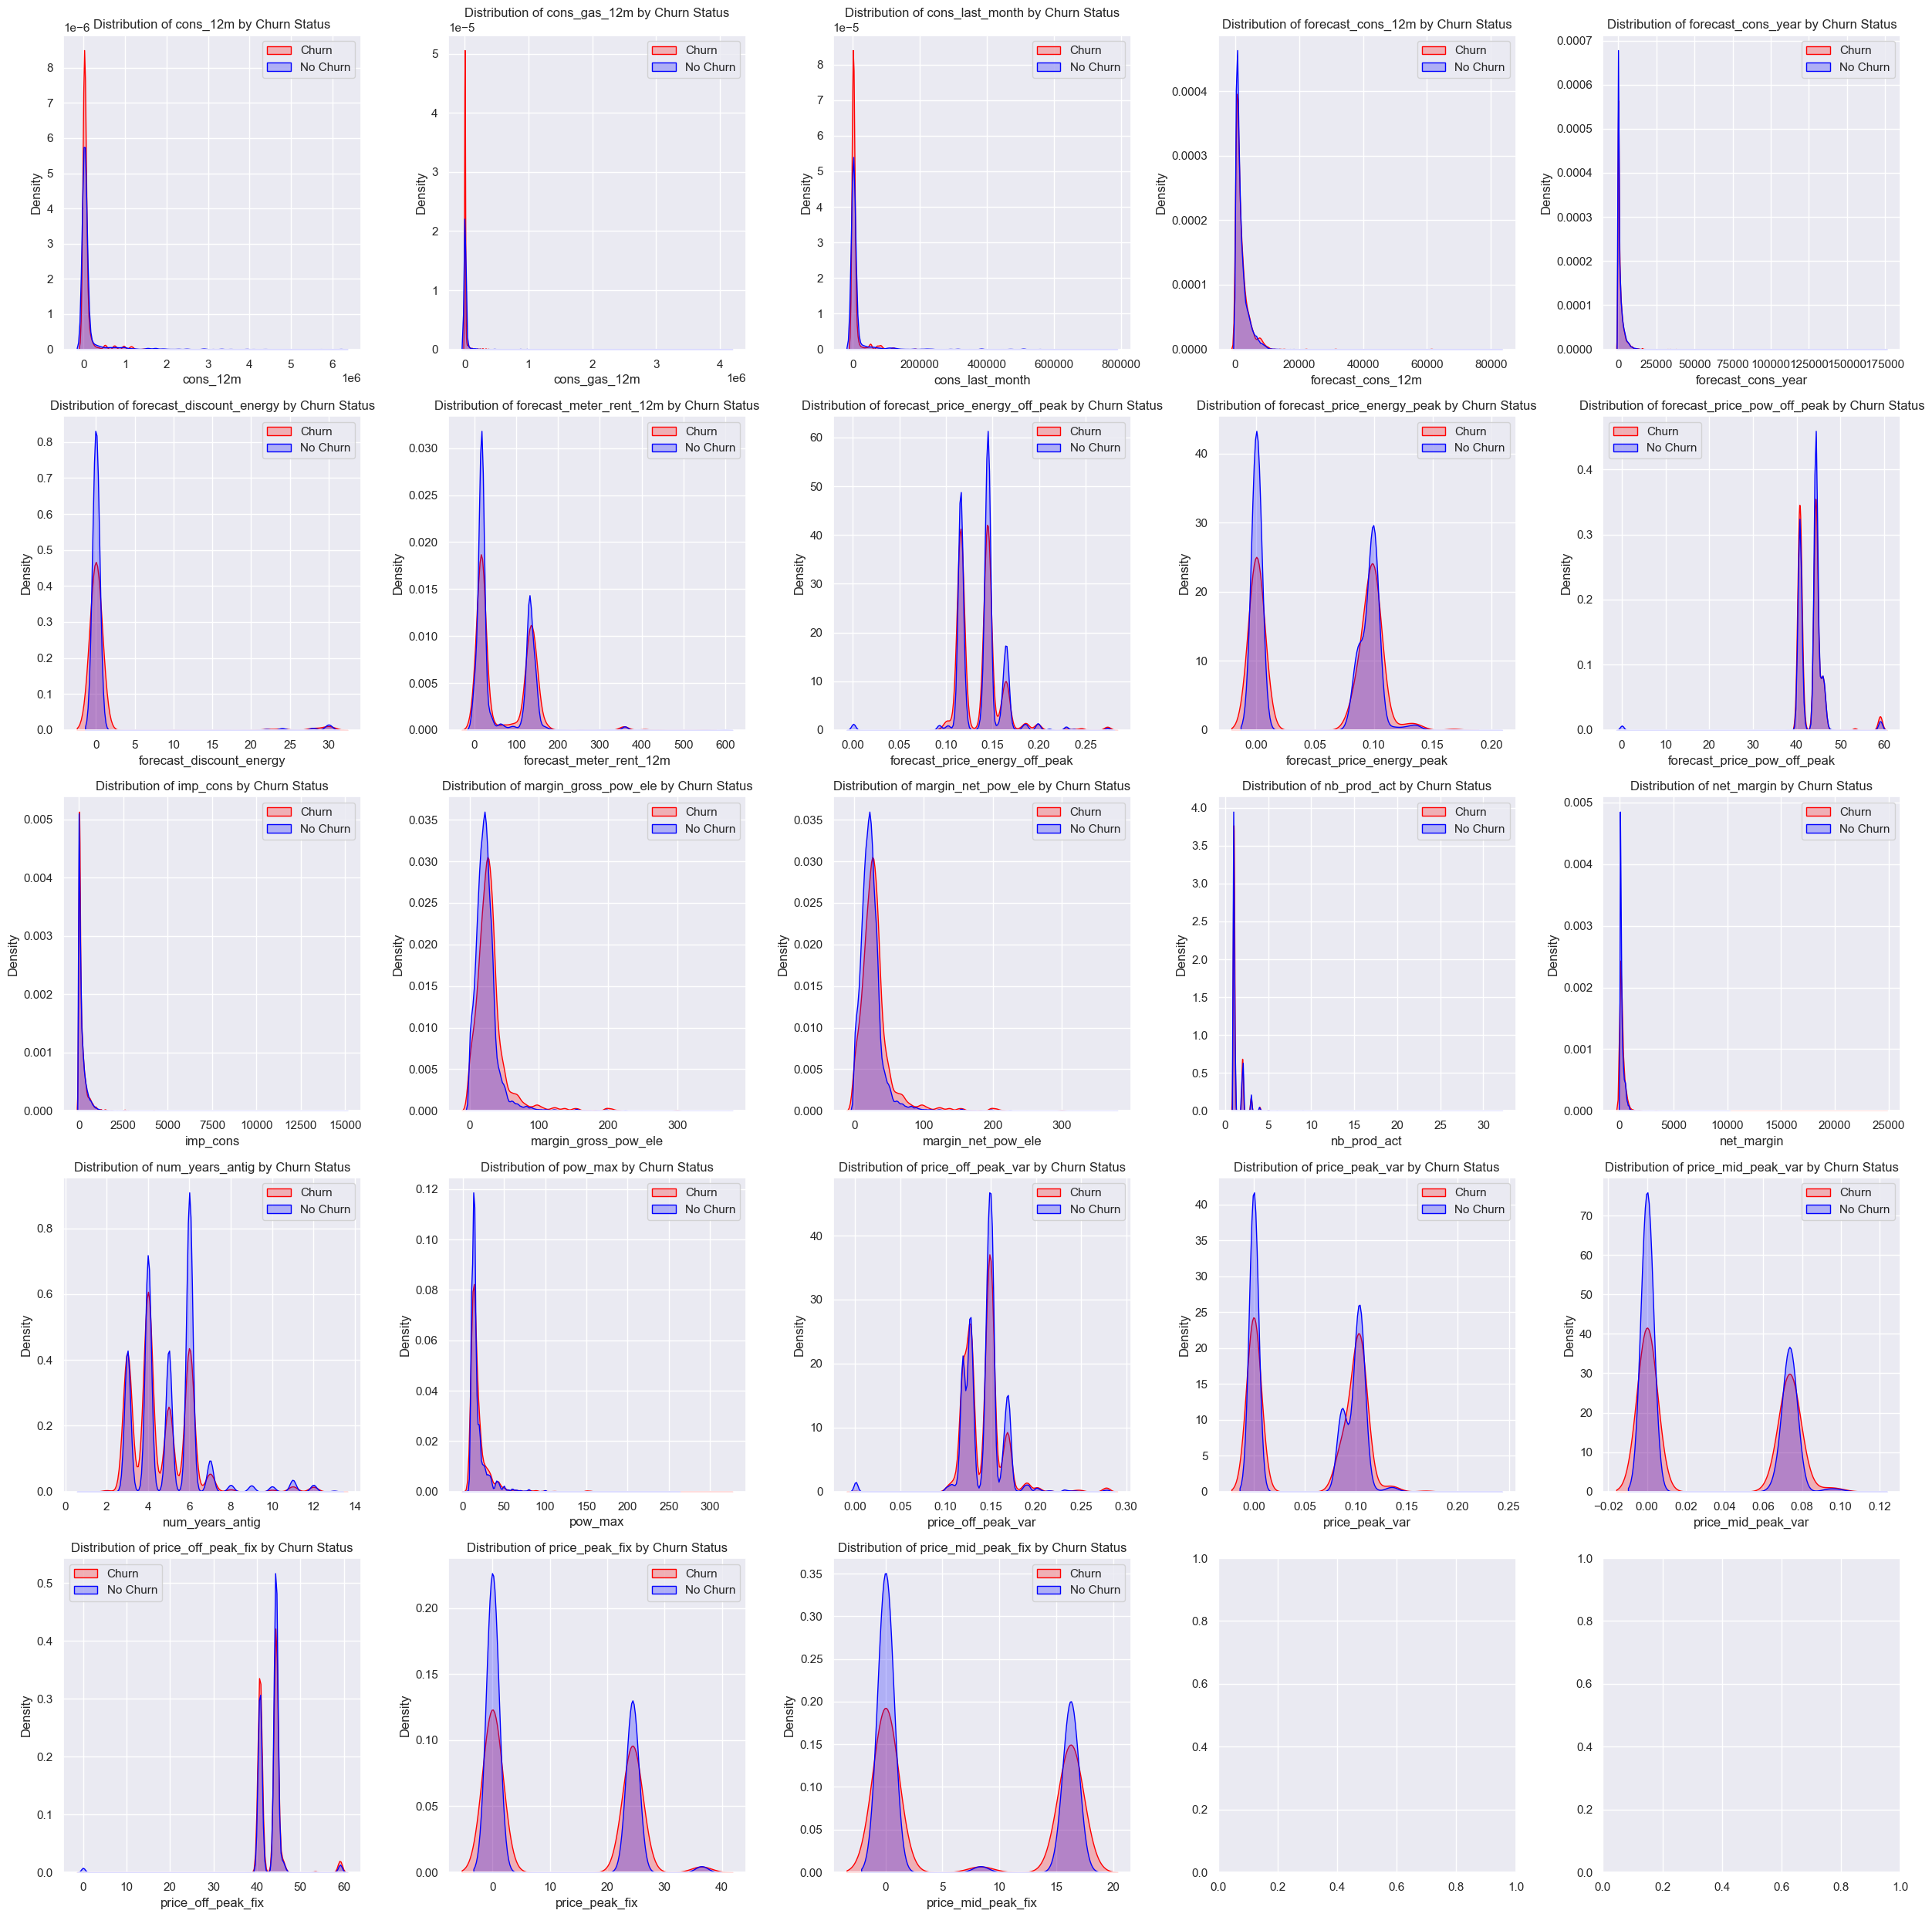

In [23]:
# Define churn and non-churn subsets
df_churn = merged_df[merged_df["churn"] == 1]
df_no_churn = merged_df[merged_df["churn"] == 0]

# Define numerical features for comparative distribution analysis
numerical_cols = [
    "cons_12m", "cons_gas_12m", "cons_last_month", "forecast_cons_12m", "forecast_cons_year",
    "forecast_discount_energy", "forecast_meter_rent_12m", "forecast_price_energy_off_peak",
    "forecast_price_energy_peak", "forecast_price_pow_off_peak", "imp_cons",
    "margin_gross_pow_ele", "margin_net_pow_ele", "nb_prod_act", "net_margin",
    "num_years_antig", "pow_max", "price_off_peak_var", "price_peak_var", "price_mid_peak_var", "price_off_peak_fix", "price_peak_fix", "price_mid_peak_fix"
]

# Plot numerical distributions for churn vs non-churn across subplots
n_cols = 5
n_rows = -(-len(numerical_cols) // n_cols)  # Ceiling division
fig, axes = plt.subplots(n_rows, n_cols, figsize=(25, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.kdeplot(df_churn[col], label="Churn", fill=True, color="red", common_norm=False, ax=axes[i])
    sns.kdeplot(df_no_churn[col], label="No Churn", fill=True, color="blue", common_norm=False, ax=axes[i])
    axes[i].set_title(f"Distribution of {col} by Churn Status")
    axes[i].legend()

plt.tight_layout()
plt.show()


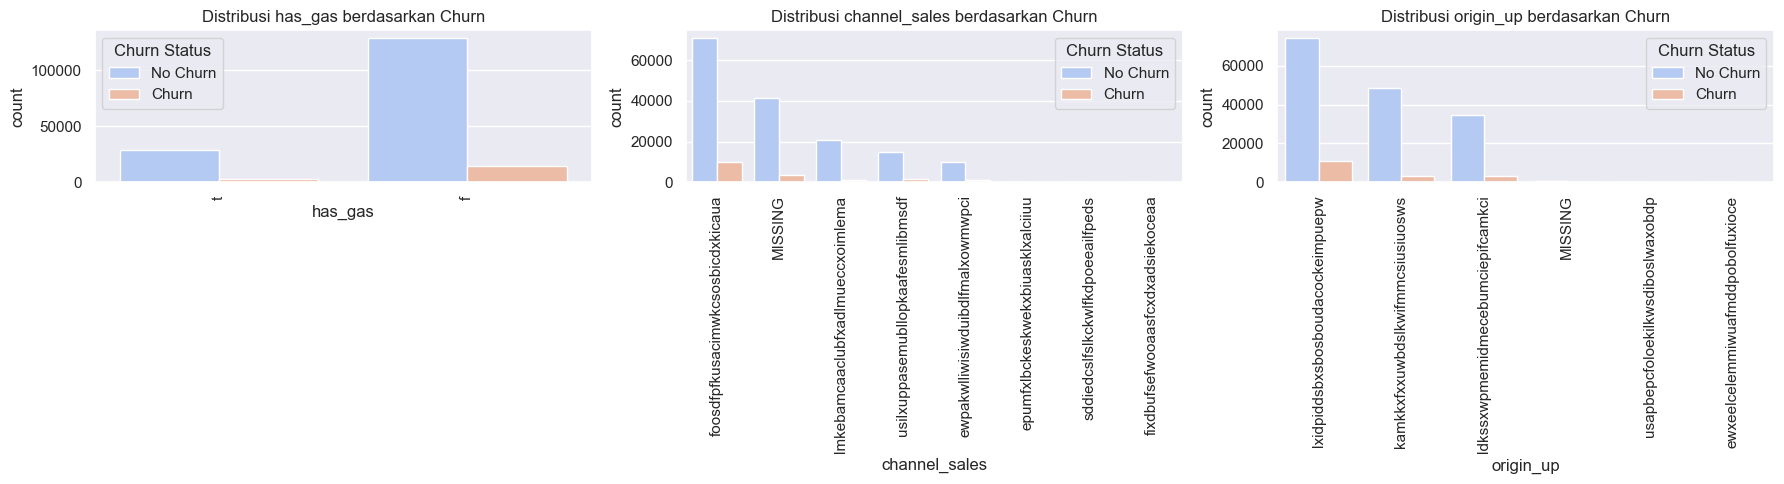

In [ ]:
categorical_columns = ["has_gas", "channel_sales", "origin_up"]

# Initialize subplots
fig, axes = plt.subplots(1, len(categorical_columns), figsize=(18, 5))

# Plot categorical distributions by churn status
for i, col in enumerate(categorical_columns):
    sns.countplot(data=merged_df, x=col, hue="churn", ax=axes[i], palette="coolwarm")
    axes[i].set_title(f"Distribution of {col} by Churn Status")
    axes[i].tick_params(axis="x", rotation=90)  # Rotate labels for readability
    axes[i].legend(title="Churn Status", labels=["No Churn", "Churn"])

# Display plot
plt.tight_layout()
plt.show()


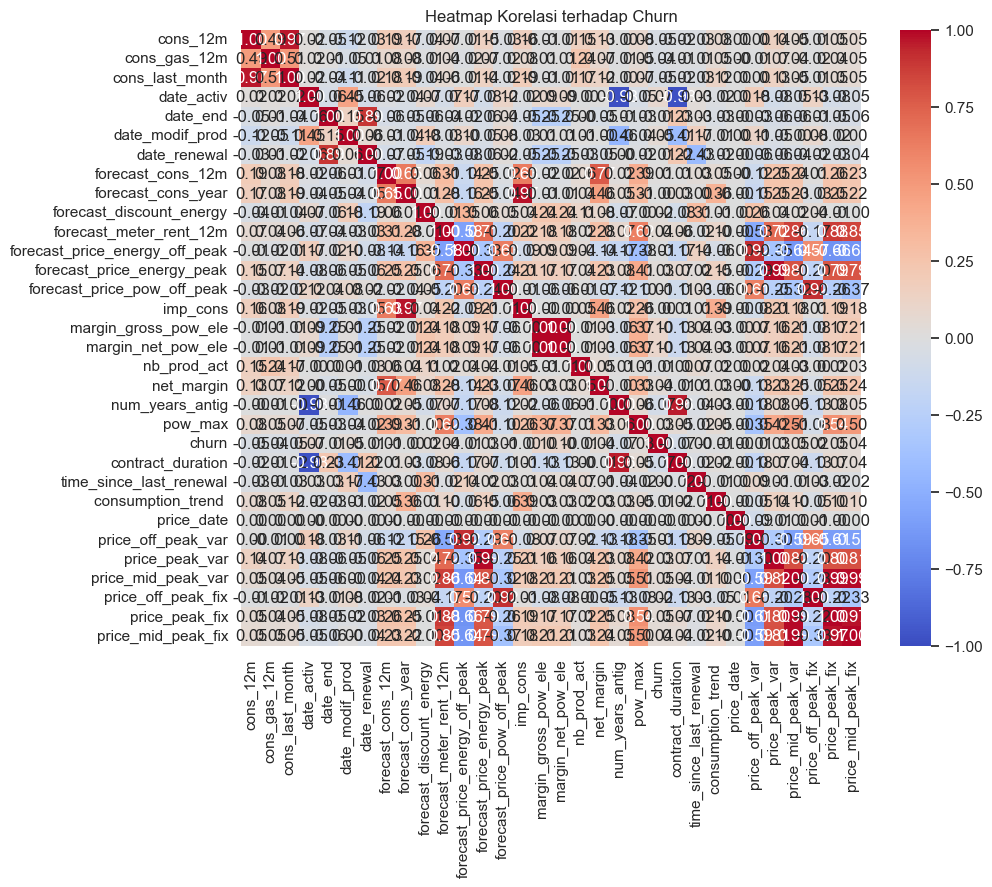

In [27]:
plt.figure(figsize=(10, 8))
sns.heatmap(merged_df.select_dtypes(exclude="object").corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap with Customer Churn")
plt.show()


---
## Conclusion

1. Most variables have similar distributions for Churn and No Churn
This suggests that most features may not have a significant impact on churn.
However, this does not mean that all features are irrelevant. There may be certain combinations of variables that have an effect on churn.

2. Some variables show different distribution patterns
For example, some variables such as forecast_price_energy_peak, price_past_1y, price_past_2y appear to have slightly different distributions for churned customers compared to non-churn customers.
This could be an indication that changes in energy prices or the costs they pay affect their decision to churn.

3. Churn is likely due to unfavorable prices or margins
Variables related to price or margins (such as margin_gross_pow_ele, price_past_2y) appear to have different distributions for churned and non-churn customers.
This could mean that customers are more likely to churn if the prices they pay increase significantly or the company's profit margins are too high.

4. Energy usage factors can also be a trigger for churn
Some energy consumption variables (such as cons_12m, cons_last_month) show little difference between churned and non-churned customers.
Perhaps churned customers are those with low energy consumption and feel the subscription fee is not worth it.